In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

df = pd.read_csv("../data/processed/cleaned_data.csv")

In [4]:
df.head(3)

,product,category,issue_description,resolution_notes,priority,status,channel,region,customer_age,customer_gender,...,escalated,sla_breached,operating_system,browser,payment_method,language,preferred_contact_time,issue_complexity_score,customer_segment,computed_resolution_time
0,web portal,account suspension,the payment was deducted from my bank account ...,data synchronization restored after backend se...,urgent,open,email,north america,31,male,...,no,yes,macos,edge,paypal,french,afternoon,4,small business,72.0
1,mobile app,performance issue,i found a bug in the latest update affecting r...,provided stepbystep troubleshooting instructio...,urgent,closed,email,south america,23,other,...,yes,yes,windows,firefox,paypal,english,afternoon,2,small business,312.0
2,web portal,performance issue,the application crashes whenever i try to uplo...,provided stepbystep troubleshooting instructio...,medium,closed,chat,europe,47,female,...,yes,yes,windows,safari,bank transfer,french,morning,4,corporate,120.0


In [6]:
print(df['priority'].value_counts())

priority
high      50241
urgent    50143
medium    49854
low       49762
Name: count, dtype: int64


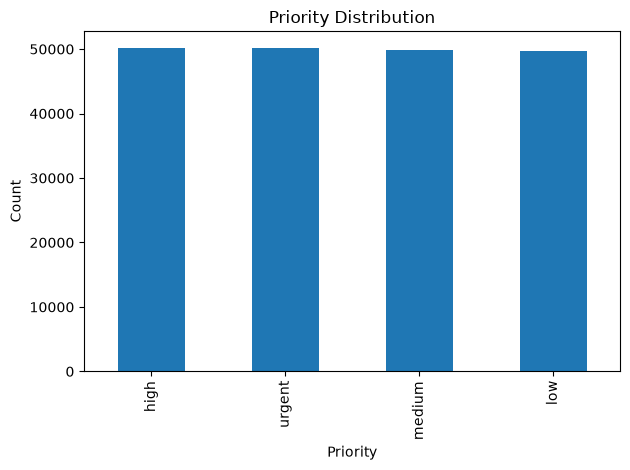

In [8]:
df['priority'].value_counts().plot(kind='bar')
plt.title('Priority Distribution')
plt.xlabel('Priority')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('../plots/priority_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
print(df['sla_breached'].value_counts())

sla_breached
yes    100043
no      99957
Name: count, dtype: int64


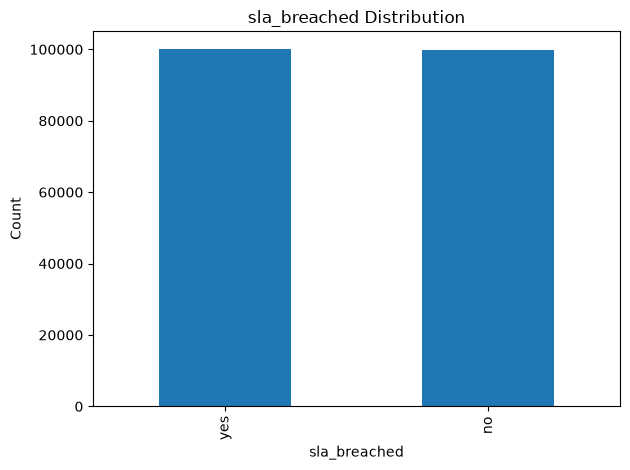

In [10]:
df['sla_breached'].value_counts().plot(kind='bar')
plt.title('sla_breached Distribution')
plt.xlabel('sla_breached')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('../plots/sla_breached_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
print(df['customer_satisfaction_score'].value_counts())

customer_satisfaction_score
2    40171
4    40086
3    40082
5    39905
1    39756
Name: count, dtype: int64


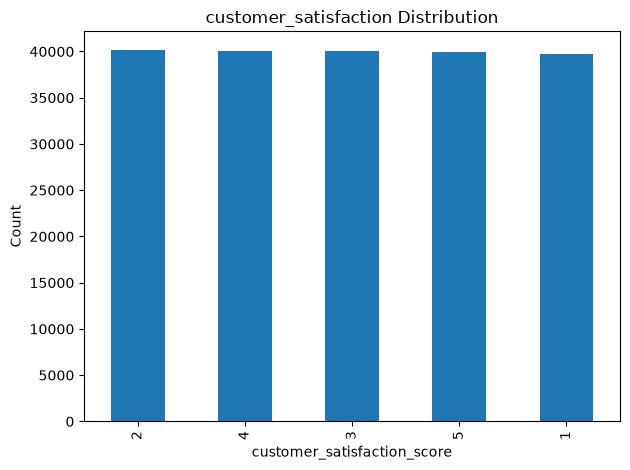

In [12]:
df['customer_satisfaction_score'].value_counts().plot(kind='bar')
plt.title('customer_satisfaction Distribution')
plt.xlabel('customer_satisfaction_score')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('../plots/customer_satisfaction_score_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

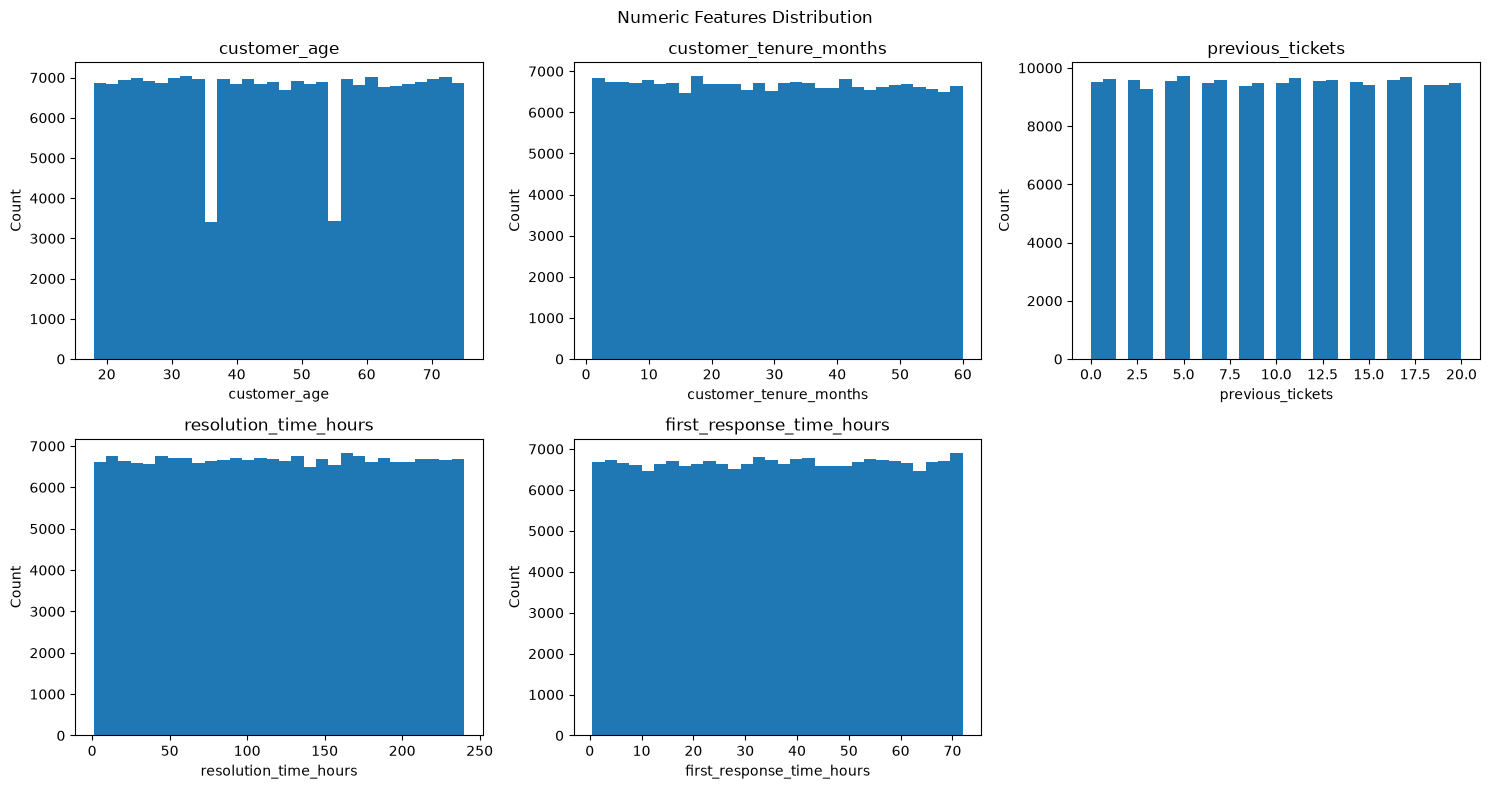

In [13]:
num_cols = ['customer_age', 'customer_tenure_months', 'previous_tickets', 
            'resolution_time_hours', 'first_response_time_hours']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    df[col].plot(kind='hist', bins=30, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

axes[-1].set_visible(False)

plt.suptitle('Numeric Features Distribution')
plt.tight_layout()
plt.savefig('../plots/numeric_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

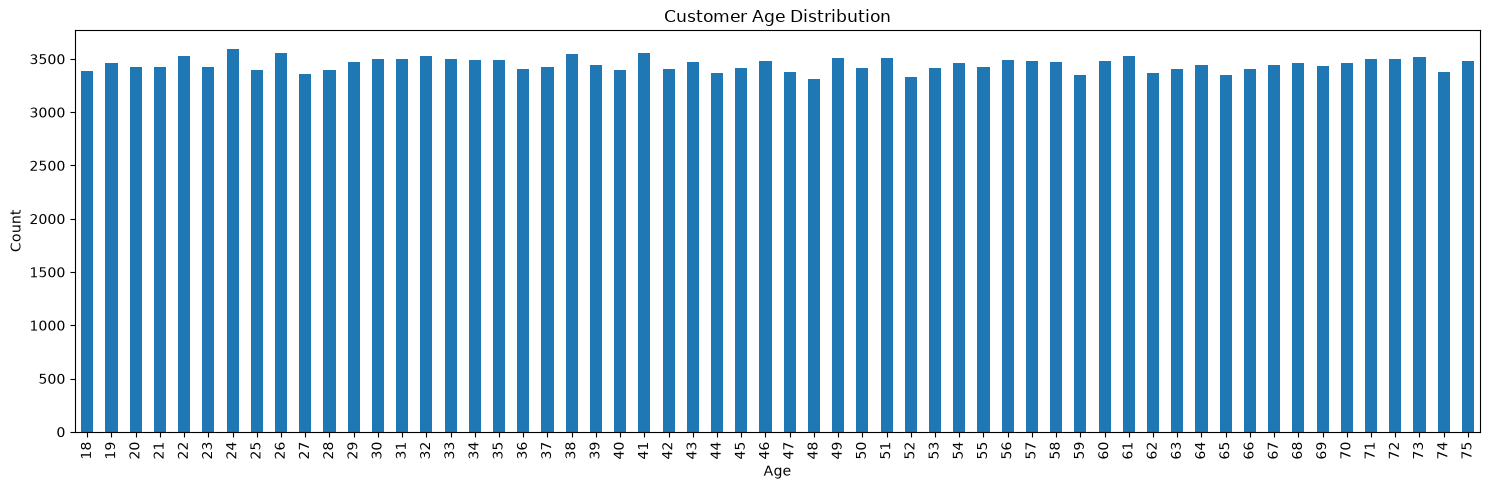

In [15]:
fig, ax = plt.subplots(figsize=(15, 5))

df['customer_age'].value_counts().sort_index().plot(kind='bar', ax=ax)
ax.set_title('Customer Age Distribution')
ax.set_xlabel('Age')
ax.set_ylabel('Count')
plt.tight_layout()
plt.savefig('../plots/customer_age_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

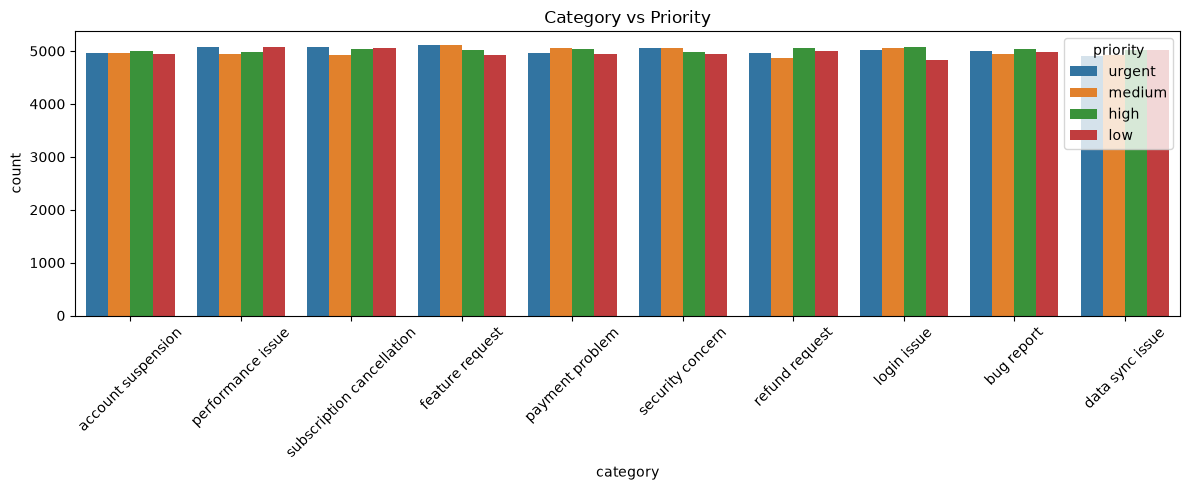

In [18]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='category', hue='priority')
plt.title('Category vs Priority')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../plots/category_vs_priority.png', dpi=150, bbox_inches='tight')
plt.show()

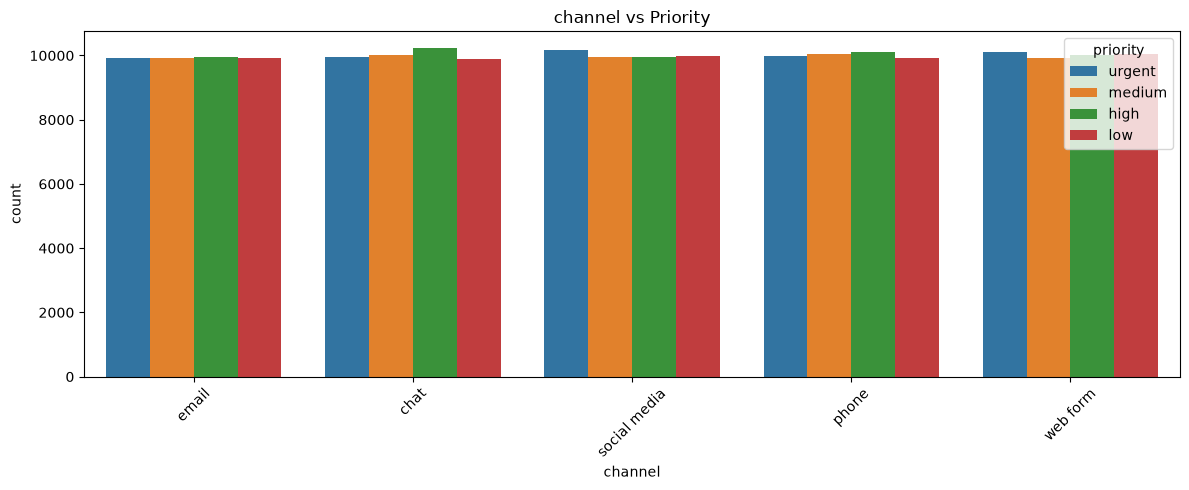

In [19]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='channel', hue='priority')
plt.title('channel vs Priority')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../plots/channel_vs_priority.png', dpi=150, bbox_inches='tight')
plt.show()

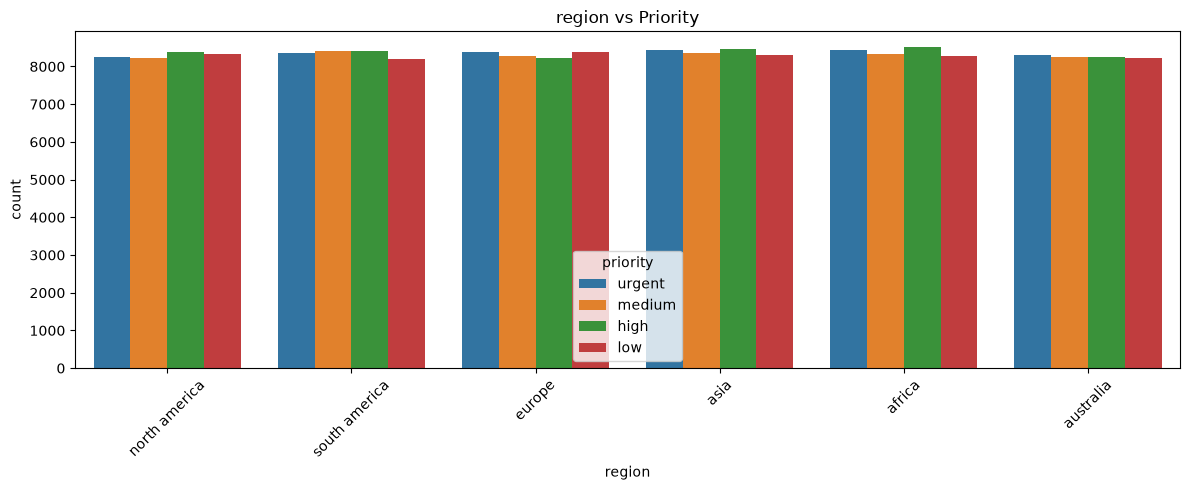

In [20]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='region', hue='priority')
plt.title('region vs Priority')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../plots/region_vs_priority.png', dpi=150, bbox_inches='tight')
plt.show()

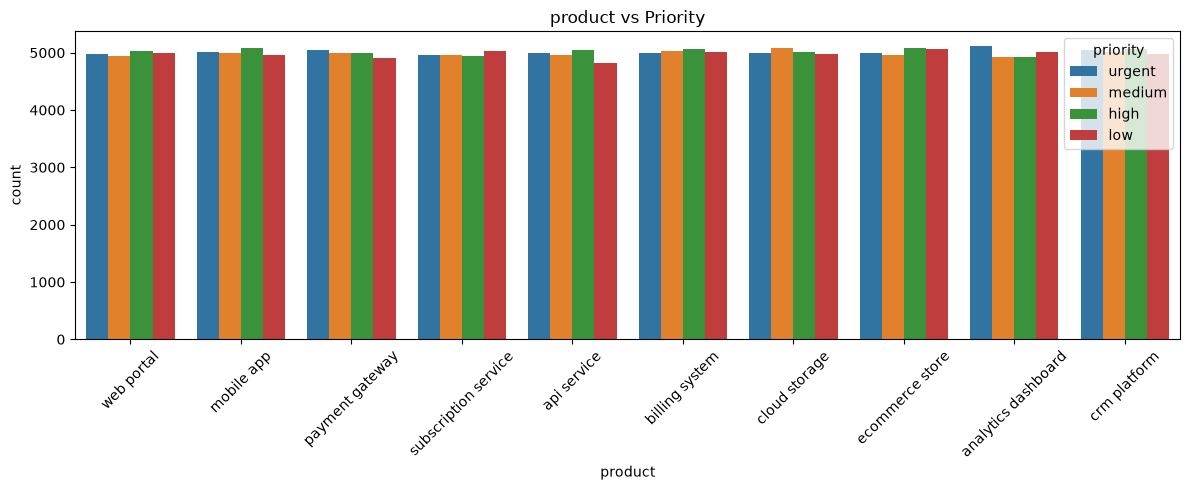

In [21]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='product', hue='priority')
plt.title('product vs Priority')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../plots/product_vs_priority.png', dpi=150, bbox_inches='tight')
plt.show()

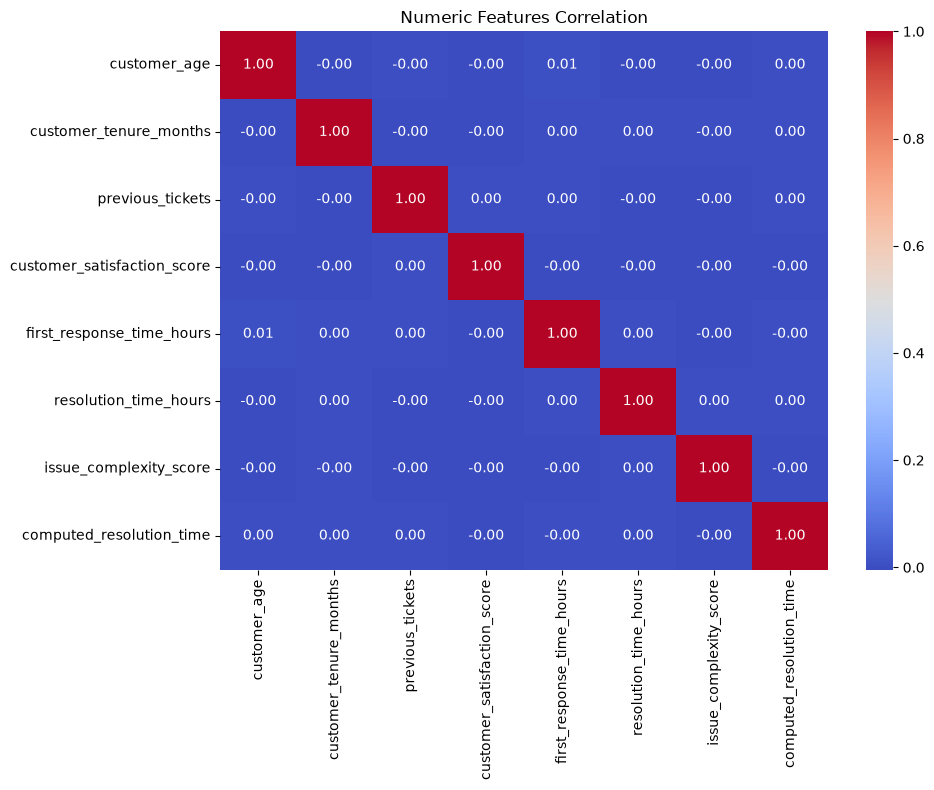

In [22]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes(include='number').corr(), 
            annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Numeric Features Correlation')
plt.tight_layout()
plt.savefig('../plots/correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

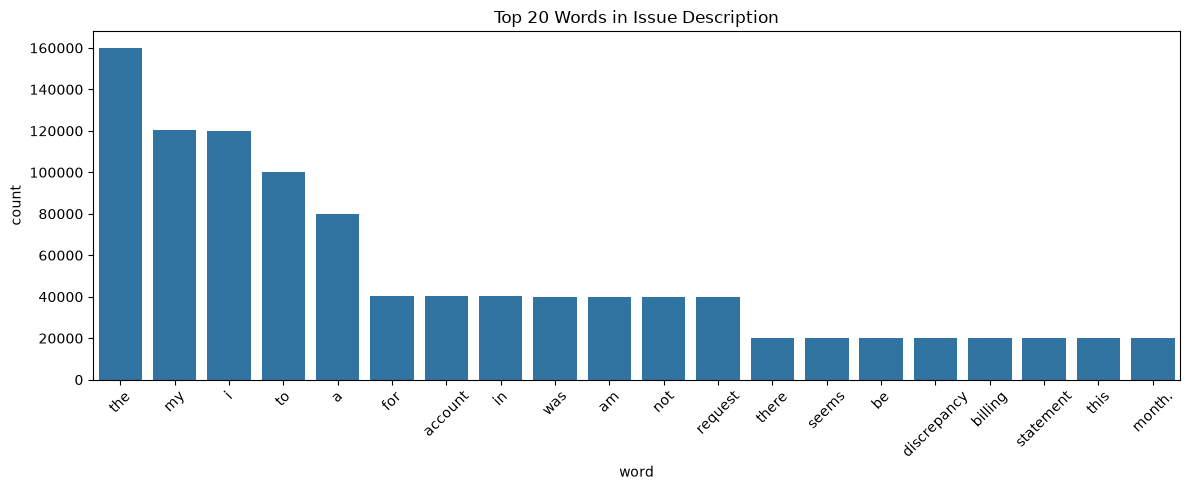

In [24]:
words = " ".join(df['issue_description']).split()
word_freq = Counter(words).most_common(20)

words_df = pd.DataFrame(word_freq, columns=['word', 'count'])

plt.figure(figsize=(12, 5))
sns.barplot(data=words_df, x='word', y='count')
plt.title('Top 20 Words in Issue Description')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../plots/top_words_issue_description.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
words = " ".join(df['issue_description']).split()
word_freq = Counter(words).most_common(20)

words_df = pd.DataFrame(word_freq, columns=['word', 'count'])

plt.figure(figsize=(12, 5))
sns.barplot(data=words_df, x='word', y='count')
plt.title('Top 20 Words in Issue Description')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../plots/top_words_issue_description.png', dpi=150, bbox_inches='tight')
plt.show()

In [2]:
print(df.groupby('priority')['category'].value_counts())

priority  category                 
high      login issue                  5081
          refund request               5054
          subscription cancellation    5044
          bug report                   5043
          payment problem              5040
          data sync issue              5020
          feature request              5017
          account suspension           4995
          performance issue            4975
          security concern             4972
low       performance issue            5075
          subscription cancellation    5063
          data sync issue              5027
          refund request               5007
          bug report                   4988
          payment problem              4948
          account suspension           4947
          security concern             4943
          feature request              4930
          login issue                  4834
medium    feature request              5106
          security concern             5

In [3]:
print(df.groupby('priority')['issue_description'].count())

priority
high      50241
low       49762
medium    49854
urgent    50143
Name: issue_description, dtype: int64
